In [24]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

# 修改为自己的学号
STUDENT_ID = 20244080223

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV","exp02")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] exp02
[学号] 20244080223
[机器指纹] 9262db88e33a32bc
[RUN_ID] 20244080223-9262db88e33a32bc


实验1 NumPy数组、数据类型与索引

In [25]:
import numpy as np

# 1. 整数、浮点、布尔 ndarray
a_int = np.array([1, 2, 3])
a_float = np.array([1.0, 2.5, 3.7])
a_bool = np.array([True, False, True])

for name, arr in [("int", a_int), ("float", a_float), ("bool", a_bool)]:
    print(name, "dtype=", arr.dtype, "shape=", arr.shape, "ndim=", arr.ndim)

int dtype= int64 shape= (3,) ndim= 1
float dtype= float64 shape= (3,) ndim= 1
bool dtype= bool shape= (3,) ndim= 1


In [26]:
# 2. arange(12) 变形
arr = np.arange(12)
print("原始:", arr)
print("(3,4):\n", arr.reshape(3, 4))
print("(2,3,2):\n", arr.reshape(2, 3, 2))

原始: [ 0  1  2  3  4  5  6  7  8  9 10 11]
(3,4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
(2,3,2):
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


In [27]:
# 3. (3,4) 索引
m = np.arange(12).reshape(3, 4)
print("第2行:", m[1], "shape:", m[1].shape)
print("第1至第3列:\n", m[:, 0:3], "shape:", m[:, 0:3].shape)
mask = m > 6
print("大于6的元素:", m[mask], "shape:", m[mask].shape)

第2行: [4 5 6 7] shape: (4,)
第1至第3列:
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] shape: (3, 3)
大于6的元素: [ 7  8  9 10 11] shape: (5,)


In [28]:
# 4. 逻辑筛选
x = np.arange(10)
print("小于2或大于7:", x[(x < 2) | (x > 7)])
print("大于3且小于7:", x[(x > 3) & (x < 7)])
print("logical_or:", x[np.logical_or(x < 2, x > 7)])
print("logical_and:", x[np.logical_and(x > 3, x < 7)])

小于2或大于7: [0 1 8 9]
大于3且小于7: [4 5 6]
logical_or: [0 1 8 9]
logical_and: [4 5 6]


In [29]:
# 5. 逐元素乘 vs 矩阵乘
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])
print("* :\n", A * B)
print("np.multiply:\n", np.multiply(A, B))
print("@ :\n", A @ B)
print("np.matmul:\n", np.matmul(A, B))

* :
 [[ 5 12]
 [21 32]]
np.multiply:
 [[ 5 12]
 [21 32]]
@ :
 [[19 22]
 [43 50]]
np.matmul:
 [[19 22]
 [43 50]]


实验2 随机抽样、统计与缺失值

In [30]:
# 1. 模拟成绩
np.random.seed(42)
scores = np.random.normal(70, 10, 1000)
scores = np.clip(scores, 0, 100)
print("样本数:", scores.size)
print("最小值:", scores.min())
print("最大值:", scores.max())
print("均值:", scores.mean())
print("标准差:", scores.std())
print("极差:", scores.max() - scores.min())

样本数: 1000
最小值: 37.58732659930927
最大值: 100.0
均值: 70.18400443523215
标准差: 9.755086339034765
极差: 62.41267340069073


In [31]:
# 2. 不放回抽样
np.random.seed(42)
pop = np.arange(1, 11)
uniform = np.random.choice(pop, size=5, replace=False)
print("均匀抽样:", uniform)

p = pop / pop.sum()
weighted = np.random.choice(pop, size=5, replace=False, p=p)
print("按大小加权抽样:", weighted)

均匀抽样: [9 2 6 1 8]
按大小加权抽样: [ 4  3 10  8  9]


In [32]:
# 3. 随机排列 vs 原地打乱
np.random.seed(42)
arr = np.arange(10)
perm = np.random.permutation(arr)
print("原数组(permutation后):", arr)
print("排列结果:", perm)

np.random.seed(42)
arr2 = np.arange(10)
np.random.shuffle(arr2)
print("shuffle后原数组:", arr2)

原数组(permutation后): [0 1 2 3 4 5 6 7 8 9]
排列结果: [8 1 5 0 7 2 9 4 3 6]
shuffle后原数组: [8 1 5 0 7 2 9 4 3 6]


In [33]:
# 4. 缺失值
scores_nan = scores.copy()
scores_nan[[9, 19, 29]] = np.nan
print("普通均值:", np.mean(scores_nan))
print("忽略nan均值:", np.nanmean(scores_nan))
print("缺失值个数:", np.isnan(scores_nan).sum())

普通均值: nan
忽略nan均值: 70.19620743160239
缺失值个数: 3


说明：np.nan 参与普通统计会把结果变为 nan（传播），需用 nanmean 等忽略缺失值的函数。

In [34]:
# 5. 内存表格变量（供实验4使用）
import pandas as pd
scores_df = pd.DataFrame({
    "index": np.arange(1000),
    "score": scores_nan
})
print(scores_df.head())

   index      score
0      0  74.967142
1      1  68.617357
2      2  76.476885
3      3  85.230299
4      4  67.658466


实验3 SciPy 数值计算与 Matplotlib 可视化

In [35]:
import matplotlib.pyplot as plt

# 解决中文显示问题
plt.rcParams['font.sans-serif'] = ['SimHei']  # 用来正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False    # 用来正常显示负号

In [36]:
from scipy.linalg import solve
import numpy as np

# 1. 线性方程组
A = np.array([[3, 1], [1, 2]])
b = np.array([9, 8])
sol = solve(A, b)
print("解:", sol)
print("验证 A@sol:", A @ sol)

解: [2. 3.]
验证 A@sol: [9. 8.]


In [37]:
from scipy.optimize import root

# 2. 求根
def f(x):
    return x**2 - 2

for guess in [1.0, -1.0]:
    res = root(f, guess)
    print(f"初值 {guess}: success={res.success}, x={res.x}, f(x)={f(res.x)}")

初值 1.0: success=True, x=[1.41421356], f(x)=[-8.8817842e-16]
初值 -1.0: success=True, x=[-1.41421356], f(x)=[-8.8817842e-16]


In [38]:
from scipy.optimize import minimize

# 3. 最小化
def g(x):
    return x**2 + x + 2

res = minimize(g, x0=0.0)
print("极小点:", res.x, "函数值:", res.fun)
print("解析解: x=-0.5, f=1.75")

极小点: [-0.50000001] 函数值: 1.75
解析解: x=-0.5, f=1.75


In [39]:
from scipy.stats import ttest_ind

# 4. 独立样本 t 检验
np.random.seed(42)
s1 = np.random.normal(0, 1, 100)
s2 = np.random.normal(1, 1, 100)
t, p = ttest_ind(s1, s2)
print("t=", t, "p=", p)
print("0.05 显著性水平下:", "拒绝原假设(均值不同)" if p < 0.05 else "不拒绝原假设")

t= -8.55145994324873 p= 3.2929614287037e-15
0.05 显著性水平下: 拒绝原假设(均值不同)


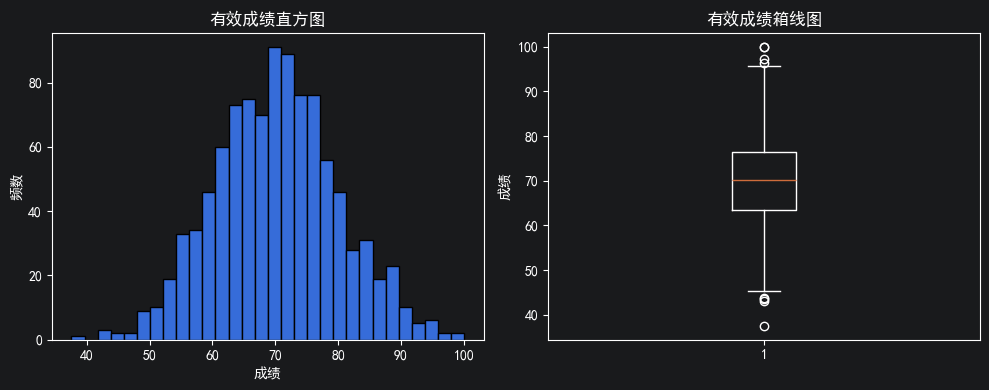

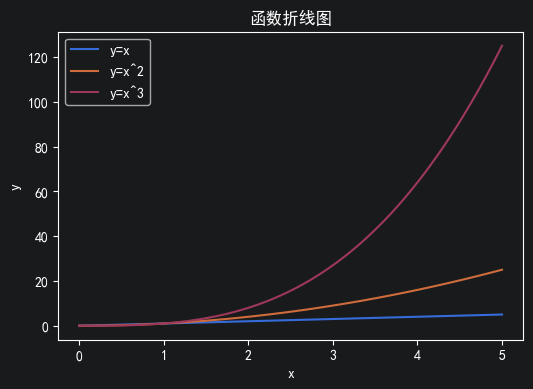

In [40]:
import matplotlib.pyplot as plt

# 5. 直方图 + 箱线图 + 折线图
valid = scores_nan[~np.isnan(scores_nan)]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(valid, bins=30, edgecolor="black")
axes[0].set_title("有效成绩直方图")
axes[0].set_xlabel("成绩")
axes[0].set_ylabel("频数")

axes[1].boxplot(valid)
axes[1].set_title("有效成绩箱线图")
axes[1].set_ylabel("成绩")
plt.tight_layout()
plt.show()

x = np.linspace(0, 5, 100)
plt.figure(figsize=(6, 4))
plt.plot(x, x, label="y=x")
plt.plot(x, x**2, label="y=x^2")
plt.plot(x, x**3, label="y=x^3")
plt.title("函数折线图")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

实验4 pandas Series、DataFrame 与内存中的 CSV 读写

In [41]:
import pandas as pd

records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records).set_index("Name")
df["Total"] = df[["Math", "English", "Python"]].sum(axis=1)
df["Average"] = df[["Math", "English", "Python"]].mean(axis=1)
print("行索引:", df.index.tolist())
print("列名:", df.columns.tolist())
print(df.head(3))
print(df.describe())

行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [42]:
# 2. loc / iloc
print("loc Carol:\n", df.loc["Carol"])
print("iloc 第3行:\n", df.iloc[2])
print("平均分>=80:\n", df[df["Average"] >= 80])

loc Carol:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
iloc 第3行:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
平均分>=80:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


In [43]:
# 3. axis=0 / axis=1 均值
print("列均值:\n", df[["Math", "English", "Python"]].mean(axis=0))
print("行均值:\n", df[["Math", "English", "Python"]].mean(axis=1))

列均值:
 Math       79.833333
English    80.833333
Python     83.666667
dtype: float64
行均值:
 Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


In [44]:
# 4. apply / agg / rank
df["MaxScore"] = df[["Math", "English", "Python"]].apply(lambda r: r.max(), axis=1)
print("每人最高分:\n", df["MaxScore"])
print("各科统计:\n", df[["Math", "English", "Python"]].agg(["min", "mean", "max"]))
print("Python排名:\n", df["Python"].rank(ascending=False))

每人最高分:
 Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
Name: MaxScore, dtype: int64
各科统计:
            Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000
Python排名:
 Name
Alice    1.0
Bob      5.0
Carol    2.0
David    6.0
Eva      3.0
Frank    4.0
Name: Python, dtype: float64


In [45]:
# 5. groupby + transform
grp = df.groupby("Group")
print("每组人数:\n", grp.size())
print("每组三科均值:\n", grp[["Math", "English", "Python"]].mean())
df["GroupPythonMean"] = grp["Python"].transform("mean")
print(df[["Group", "Python", "GroupPythonMean"]])

每组人数:
 Group
A    3
B    3
dtype: int64
每组三科均值:
             Math    English     Python
Group                                 
A      79.666667  83.333333  87.000000
B      80.000000  78.333333  80.333333
      Group  Python  GroupPythonMean
Name                                
Alice     A      95        87.000000
Bob       A      80        87.000000
Carol     B      89        80.333333
David     B      70        80.333333
Eva       A      86        87.000000
Frank     B      82        80.333333


In [46]:
# 6. filter 保留 Python 均值 >= 80 的组
filtered = df.groupby("Group").filter(lambda g: g["Python"].mean() >= 80)
print(filtered)

      Group  Math  English  Python  Total    Average  MaxScore  \
Name                                                             
Alice     A    88       90      95    273  91.000000        95   
Bob       A    72       68      80    220  73.333333        80   
Carol     B    91       85      89    265  88.333333        91   
David     B    65       73      70    208  69.333333        73   
Eva       A    79       92      86    257  85.666667        92   
Frank     B    84       77      82    243  81.000000        84   

       GroupPythonMean  
Name                    
Alice        87.000000  
Bob          87.000000  
Carol        80.333333  
David        80.333333  
Eva          87.000000  
Frank        80.333333  


In [47]:
# 7. 协方差与相关系数矩阵
cov = df[["Math", "English", "Python"]].cov()
corr = df[["Math", "English", "Python"]].corr()
print("协方差:\n", cov)
print("相关系数:\n", corr)

协方差:
               Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667
相关系数:
              Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000
